# Analyze Xenium data

Xenium is an imaging-based spatial transcriptomics machine from 10xGenomics. A tissue sliceis probed for a fixed panel of genes and each singel RNA molecule is detected as a dot at its exact location. The software outlines cells and counts which RNA dots fall inside each cell. 

### Aim
Use single-cell spatial transcriptomics (Xenium) from lung cancer tissue to identify cell types and describe how they are arranged in the tissue.

### Data:
Human lunc cancer (FFPE tissue), 162,254 cells x 377 genes from 10xGenomics

### Workflow:
1. Read the raw Xenium output
2. QC and filtering
3. The usual Scanpy pipeline: noramlise, PCA, UMAP and Leiden clustering
4. Spatial statistics: centrality, co-occurrence, neighbourhood enrichment, Moran's I
5. Plot on the tissue image

Comparison of Visium, IMC and Xenium

| |Visium|IMC|Xenium|
|---|---|---|---|
|Masures|RNA, whole genome| ~40 proteins| RNA, ~500 gene-panel|
|Unit|Spot (1 to 10 cells) | Cell | Cell|
|with | H&E image | Marker images | Location of every RNA molecule|

In [1]:
import spatialdata as sd
from spatialdata_io import xenium

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq
import os

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
xenium_path = "./Xenium"
zarr_path = "./Xenium.zarr"

if not os.path.exists(zarr_path):
    sdata = xenium(xenium_path)
    sdata.write(zarr_path)

sdata = sd.read_zarr(zarr_path)
sdata

no parent found for <ome_zarr.reader.Label object at 0x13d47a3c0>: None
no parent found for <ome_zarr.reader.Label object at 0x13d54cf50>: None


SpatialData object, with associated Zarr store: /Users/kimseyeong/Desktop/Spatial dataset analysis project/Xenium.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 17098, 51187), (4, 8549, 25593), (4, 4274, 12796), (4, 2137, 6398), (4, 1068, 3199)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (17098, 51187), (8549, 25593), (4274, 12796), (2137, 6398), (1068, 3199)
│     └── 'nucleus_labels': DataTree[yx] (17098, 51187), (8549, 25593), (4274, 12796), (2137, 6398), (1068, 3199)
├── Points
│     └── 'transcripts': DataFrame with shape: (12165021, 11) (3D points)
├── Shapes
│     └── 'cell_boundaries': GeoDataFrame shape: (162254, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (162254, 377)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes)

- image - morphology_focus with 4 channels (multimodal segmentation stains), 17,098 x 51,187 pixels
- labels - cell_labels, nucleus_labels - segmentation masks
- points - transcripts - about 12.2 million RNA molecules with x (width), y (height), z (how deep) and gene name 
- shapes - cell_boundaries - 162,254 cell outlines
- tables - table - the AnnData 162,254 cells x 377 genes, the counts of RNA dots inside each cell

### Note on data version
The tutorial reports 161,000 cells × 480 genes. The dataset currently available from 10x Genomics
(FFPE Human Lung Cancer with Xenium Multimodal Cell Segmentation, Xenium Onboard Analysis v2.0)
contains 162,254 cells × 377 genes, with a 4-channel morphology image and multimodal cell segmentation.
Newer versions of `spatialdata-io` also create different shape layers (`cell_boundaries` only, no `cell_circles`).
Results (cluster numbers, top Moran's I genes) therefore differ slightly from the tutorial.

In [3]:
# Get the AnnData
adata = sdata.tables["table"]
adata

AnnData object with n_obs × n_vars = 162254 × 377
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'z_level', 'nucleus_count', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'
    layers: None (.X)

In [4]:
adata.obs

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,region,z_level,nucleus_count,cell_labels
aaaadpbp-1,aaaadpbp-1,0,0,0,0,0,0,68.456877,NaN,cell_labels,0.0,0.0,1
aaaaficg-1,aaaaficg-1,19,0,0,0,0,19,49.130002,21.268595,cell_labels,0.0,1.0,2
aaabbaka-1,aaabbaka-1,53,0,0,0,0,53,119.618911,74.778753,cell_labels,0.0,1.0,3
aaabbjoo-1,aaabbjoo-1,29,0,0,0,0,29,94.241097,59.109533,cell_labels,0.0,1.0,4
aaablchg-1,aaablchg-1,42,0,0,1,0,43,120.341411,52.426408,cell_labels,0.0,1.0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
ojaaphhh-1,ojaaphhh-1,3,0,0,0,0,3,26.913126,11.153594,cell_labels,5.0,1.0,162250
ojabeldf-1,ojabeldf-1,6,0,0,0,0,6,5.418750,5.418750,cell_labels,7.0,1.0,162251
ojacfbid-1,ojacfbid-1,0,0,0,0,0,0,6.502500,6.502500,cell_labels,5.0,1.0,162252
ojacfhhg-1,ojacfhhg-1,2,0,0,0,0,2,7.089532,7.089532,cell_labels,5.0,1.0,162253


In [5]:
adata.obsm["spatial"]

array([[ 206.08981323, 1495.89819336],
       [ 201.76582336, 1816.21081543],
       [ 179.02450562, 2167.25390625],
       ...,
       [4463.31298828, 1576.60400391],
       [4619.91552734, 1454.3223877 ],
       [4620.28125   , 1528.10766602]], shape=(162254, 2))

## Calculate quality control metrics

In [6]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)
# measure the percentage of counts in the top 10, 20, 50, and 150 genes for each cell 
# to see how dominated the cell is by a few genes, which can indicate low-quality cells or technical artifacts

In [7]:
# checking the fake signal from negative DNA probes and decoding control codewords, which should be low in a good quality dataset
cprobes = (
    adata.obs["control_probe_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
cwords = (
    adata.obs["control_codeword_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
print(f"Negative DNA probe count % : {cprobes}")
print(f"Negative decoding count % : {cwords}")

Negative DNA probe count % : 0.0042798755460108405
Negative decoding count % : 0.0018622359246001363


<Axes: title={'center': 'Nucleus ratio'}, ylabel='Count'>

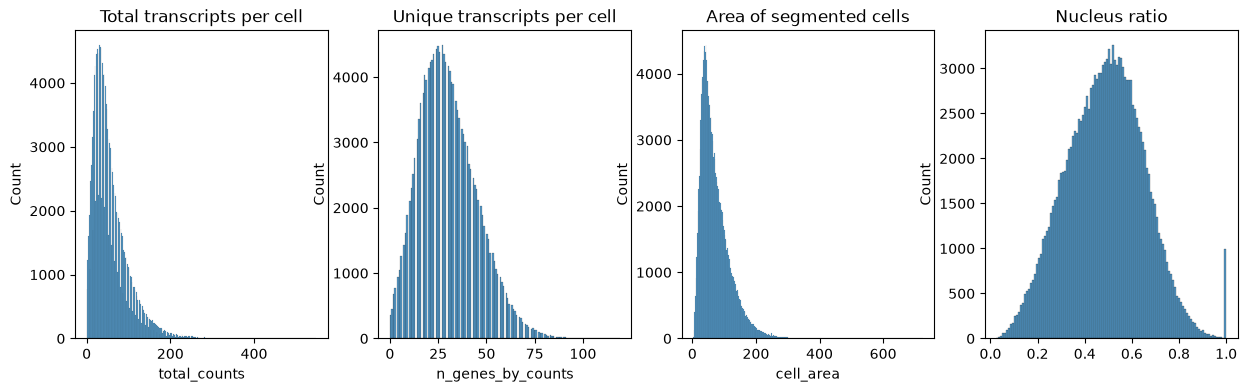

In [8]:
# four histograms shows the distribution of 
# total RNA per cell
# number of genes per cell
# cell size
# nucleus ratio (nucleus area / cell area)
# to check the quality of the dataset and see if there are any outliers or low-quality cells that need to be filtered out
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)


axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata.obs["nucleus_area"] / adata.obs["cell_area"],
    kde=False,
    ax=axs[3],
)

QC distributions differ from the tutorial because this data version uses multimodal cell segmentation
(cell boundary and interior stains) rather than nucleus expansion: cells are smaller, contain fewer
transcripts and have a higher nucleus-to-cell ratio. A small group of cells has a ratio of exactly 1
(cell outline = nucleus outline).

In [9]:
# filtering out cells with less than 10 RNA molecules and genes shown in less than 5 cells
sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)

Filtering removed 7,782 of 162,254 cells, leaving 154,472 cells.

In [10]:
# normalization and log transformation
# pca summarises 377 genes into a few main patterns, neighbor graph to link cells with similar patterns, 
# umap to draw 2d picture of them, and leiden clustering
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata)

/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_99924/2302678873.py:10: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)


## Visualize annotation on UMAP and spatial coordinates

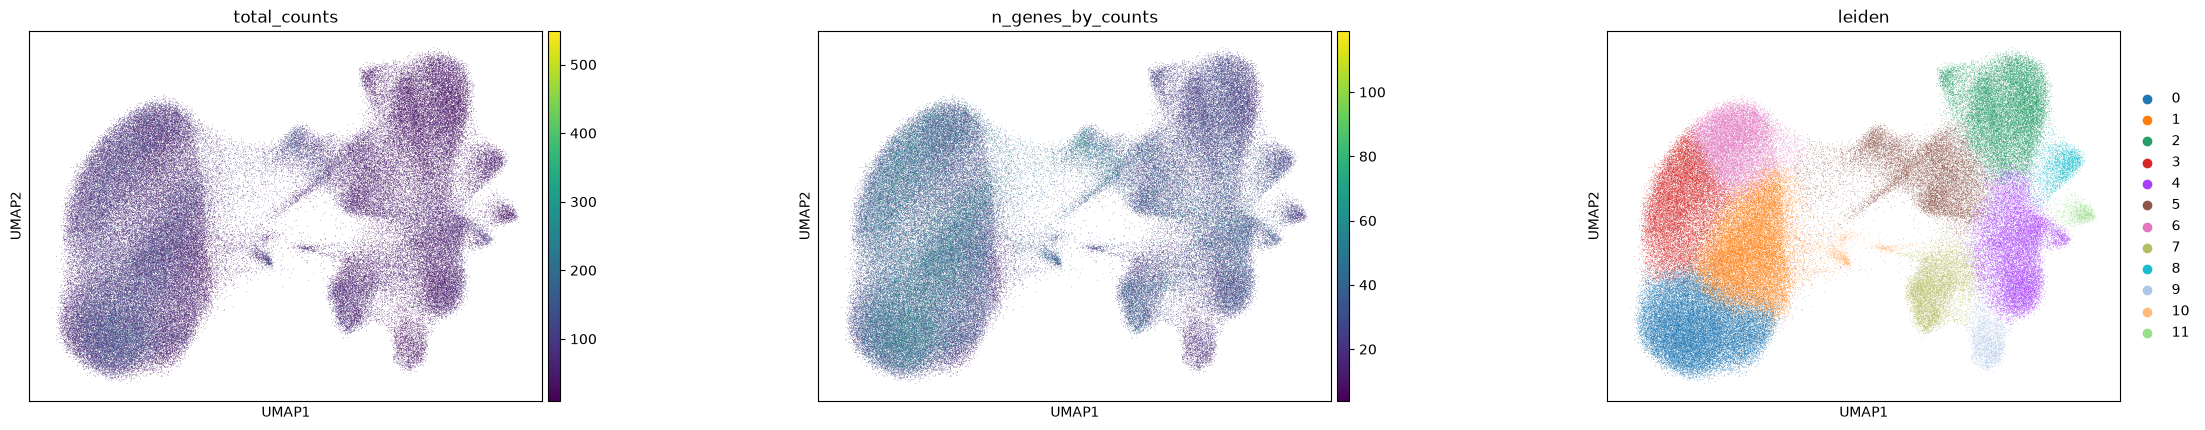

In [11]:
sc.pl.umap(
    adata,
    color=[
        "total_counts",
        "n_genes_by_counts",
        "leiden",
    ],
    wspace=0.4,
)

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


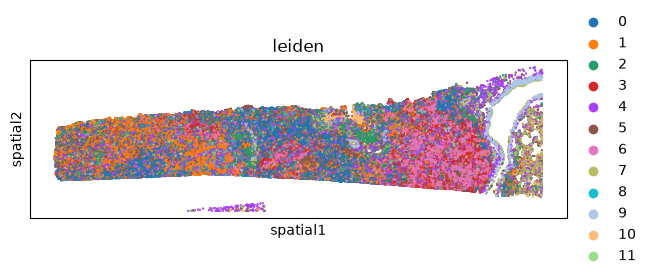

In [12]:
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color=[
        "leiden",
    ],
    wspace=0.4,
)

In [13]:
# Building a spatial neighborhood graph
sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_99924/972393525.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)


In [14]:
# Compute centrality scores
# this describe each clusters' position in the tissue network like central or peripheral, tight or loose clumps, neighbouring with other clusters, etc.
sq.gr.centrality_scores(adata, cluster_key="leiden")

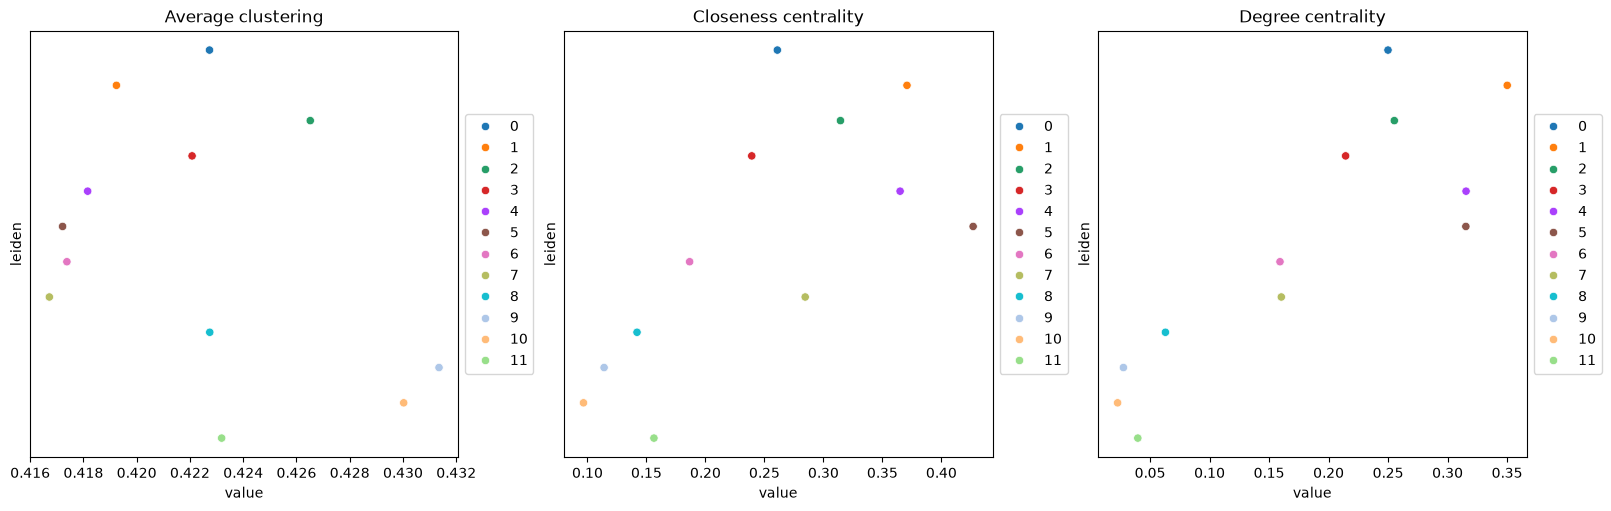

In [15]:
sq.pl.centrality_scores(adata, cluster_key="leiden", figsize=(16, 5))

### not in tutorial - highlight clusters 4 and 9 lining the airway-like structure

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


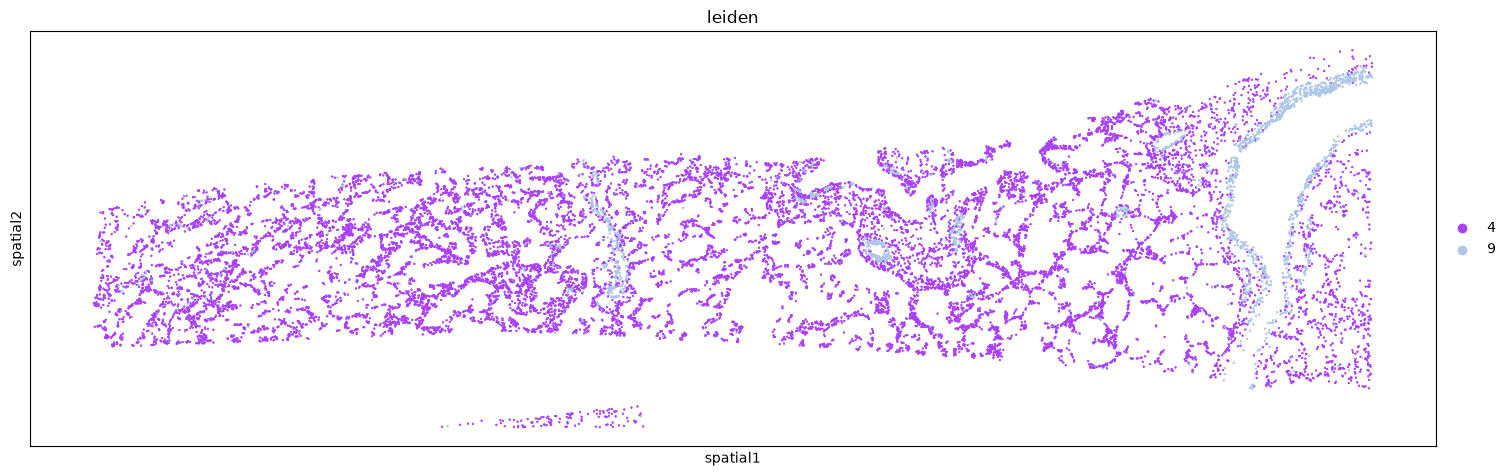

In [16]:
sq.pl.spatial_scatter(adata, library_id="spatial", shape=None, color="leiden",
                      groups=["4", "9"], size=1, figsize=(15, 5))

### Compute co-occurrence probability

In [17]:
# take a random subsample of 50% of the cells to speed up the computation of spatial statistics
sdata.tables["subsample"] = sc.pp.subsample(adata, fraction=0.5, copy=True)
adata_subsample = sdata.tables["subsample"]

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


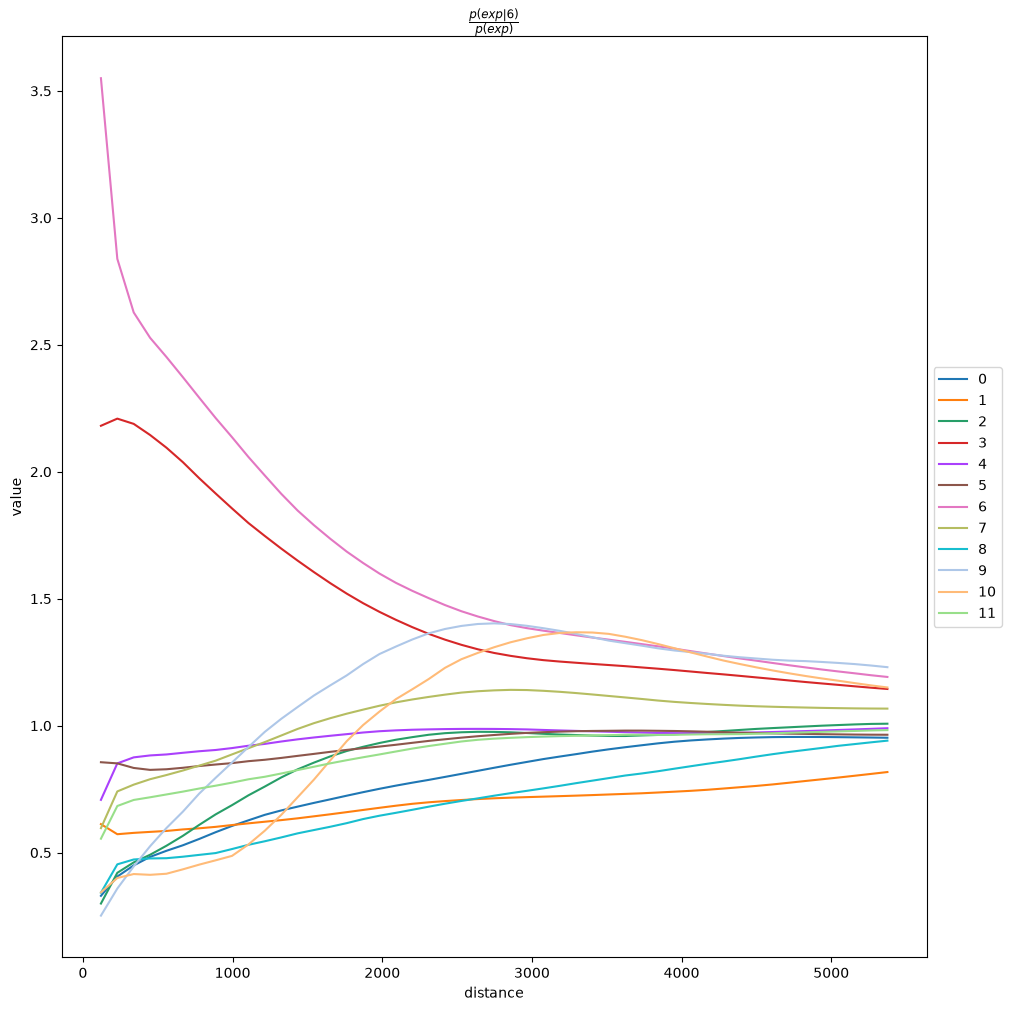

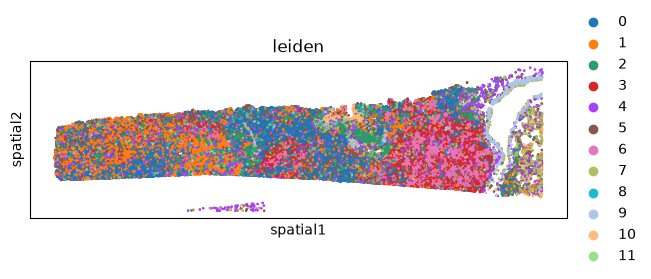

In [ ]:
# co-occurrence analysis to see which clusters are more likely to be found together in the tissue
sq.gr.co_occurrence(
    adata_subsample,
    cluster_key="leiden",
)
sq.pl.co_occurrence(
    adata_subsample,
    cluster_key="leiden",
    clusters="6",  # tutorial uses "12"; this run has clusters 0-11
    figsize=(10, 10),
)
sq.pl.spatial_scatter(
    adata_subsample,
    color="leiden",
    shape=None,
    size=2,
)

### Neighbourhood enrichment analysis
Which clusters neighbour each other more than expected by chance? Observed neighbour counts on the spatial graph are compared with 1,000 random shuffles of the cluster labels to give a z-score.

In [19]:
sq.gr.nhood_enrichment(adata, cluster_key="leiden")

100%|██████████| 1000/1000 [00:10<00:00, 96.73/s]


/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


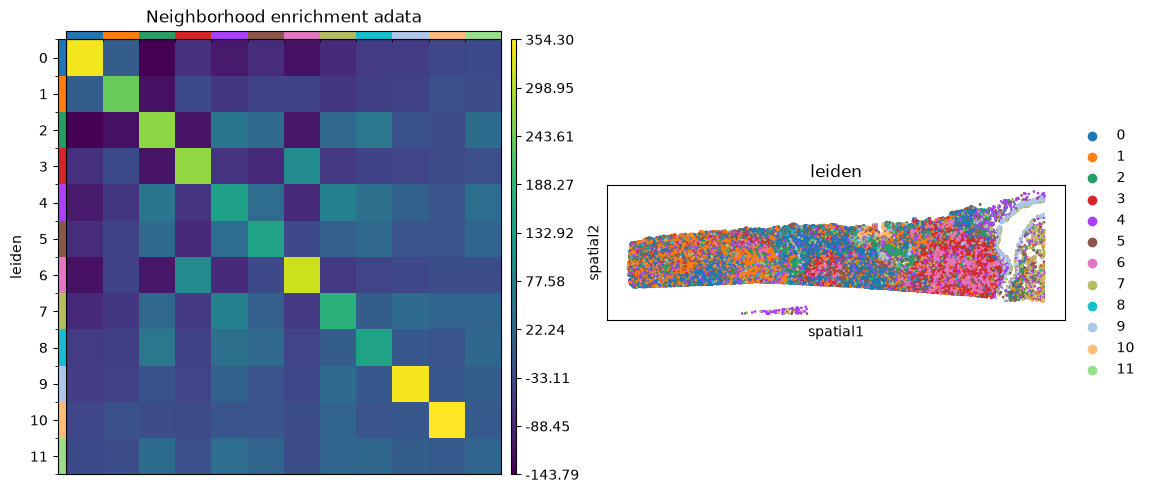

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
sq.pl.nhood_enrichment(
    adata,
    cluster_key="leiden",
    figsize=(8, 8),
    title="Neighborhood enrichment adata",
    ax=ax[0],
)
sq.pl.spatial_scatter(adata_subsample, color="leiden", shape=None, size=2, ax=ax[1])

### Compute Moran's I score
Moran's I gives one score per gene, summarising across all neighbouring cell pairs whether neighbours have
similar expression (I near 1 = spatial pattern, near 0 = random). Here it is computed on ~77,000 cells
(the 50% subsample) using Delaunay neighbours.


calculation example:
Gene A high on one side and low on the other
|values | 1| 1| 1| 9| 9| 9| average = 5|
|---|---|---|---|---|---|---|---|
|differences|-4|-4|-4|+4|+4|+4| |

----
|neighbour pair | product|
|---|---|
|spot 1-2| -4 x -4 = 16|
|spot 2-3| -4 x -4 = 16|
|spot 3-4| -4 x 4 = -16|
|spot 4-5| 4 x 4 = 16|
|spot 5-6| 4 x 4 = 16|

Therefore 
average = (16 +16 - 16 + 16 + 16)/ 5 pairs = 48 / 5 = 9.6
variance = average of squared differences from the mean
4^2 or -4^2 = 16

Moran's I = 9.6 / 16 = 0.6

In [22]:
sq.gr.spatial_neighbors(adata_subsample, coord_type="generic", delaunay=True)
sq.gr.spatial_autocorr(
    adata_subsample,
    mode="moran",
    n_perms=100,
    n_jobs=1,
)
adata_subsample.uns["moranI"].head(10)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/df/6k2bwzwx1t921dqfsfctvxrc0000gn/T/ipykernel_99924/2406646513.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata_subsample, coord_type="generic", delaunay=True)
100%|██████████| 100/100 [16:28<00:00,  9.89s/]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
C20orf85,0.580415,0.0,0.000004,0.0,0.009901,0.000007,0.0,0.0,0.011628
CYP2B6,0.559513,0.0,0.000004,0.0,0.009901,0.000007,0.0,0.0,0.011628
MALL,0.495123,0.0,0.000004,0.0,0.009901,0.000007,0.0,0.0,0.011628
C1orf194,0.485502,0.0,0.000004,0.0,0.009901,0.000006,0.0,0.0,0.011628
MS4A1,0.474634,0.0,0.000004,0.0,0.009901,0.000007,0.0,0.0,0.011628
MYC,0.469961,0.0,0.000004,0.0,0.009901,0.000006,0.0,0.0,0.011628
EPCAM,0.429761,0.0,0.000004,0.0,0.009901,0.000006,0.0,0.0,0.011628
CAPN8,0.419282,0.0,0.000004,0.0,0.009901,0.000005,0.0,0.0,0.011628
TCIM,0.390758,0.0,0.000004,0.0,0.009901,0.000005,0.0,0.0,0.011628
MYH11,0.385297,0.0,0.000004,0.0,0.009901,0.000005,0.0,0.0,0.011628


- C20orf85 and C1orf194 - markers of ciliated airway cells.
- MYH11 - smooth muscle.
- MS4A1 - B cells, which often sit in clumps.

- The tutorial's top Moran's I genes (AREG, MET) are not in this panel, so this dataset's own top genes are plotted.
- Current spatialdata-io (≥ 0.6) links the table to `cell_labels` instead of `cell_circles`, and current spatialdata-plot
  no longer has `use_raw`, so the final plot uses `render_labels("cell_labels", ...)`.

/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/Users/kimseyeong/Desktop/Spatial dataset analysis project/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


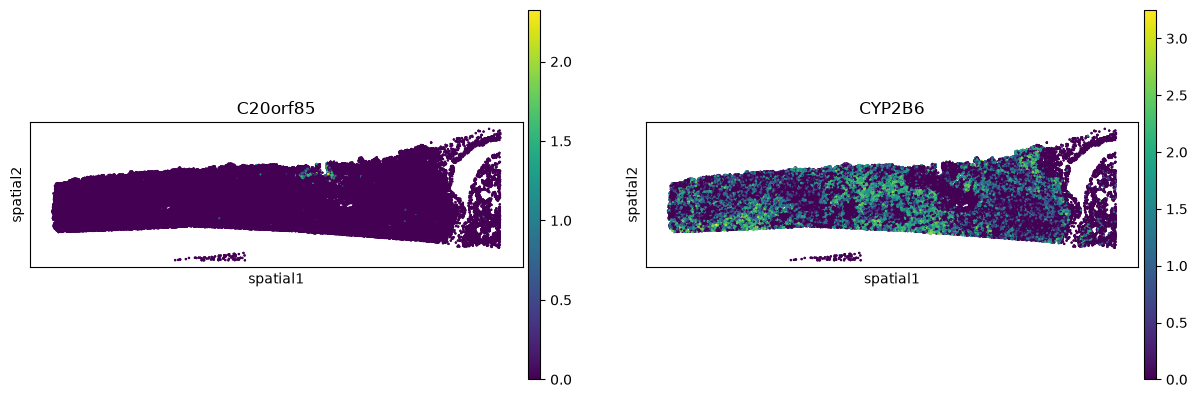

In [23]:
# Visualise the top Moran's I genes on the tissue
# (the tutorial's AREG and MET are not in this dataset's gene panel, so this dataset's own top two genes are used)
sq.pl.spatial_scatter(
    adata_subsample,
    library_id="spatial",
    color=[
        "C20orf85",
        "CYP2B6",
    ],
    shape=None,
    size=2,
    img=False,
)

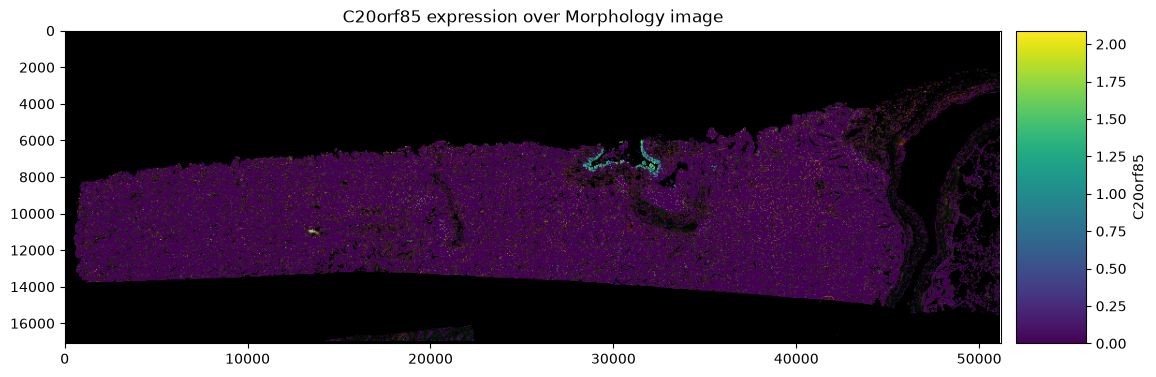

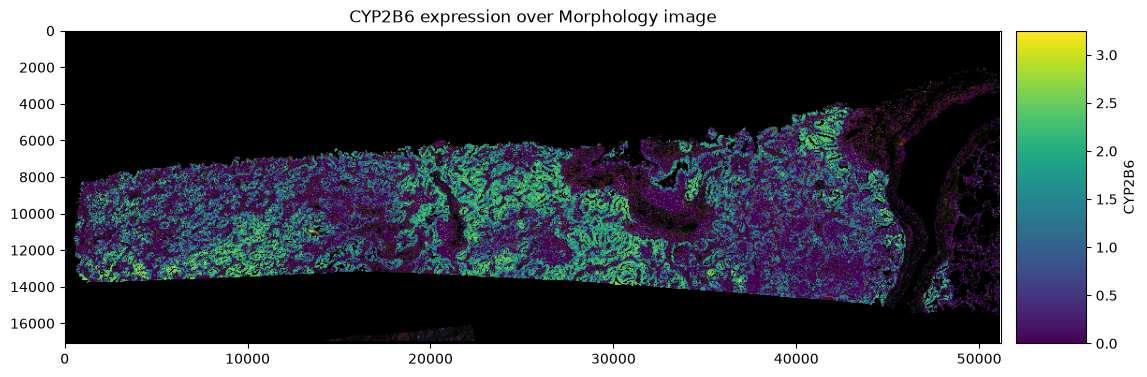

In [26]:
# shows genes on the real microscopy image of the tissue to see the expression on the actual tissue morphology
import spatialdata_plot

gene_name = ["C20orf85", "CYP2B6"]
for name in gene_name:
    sdata.pl.render_images("morphology_focus").pl.render_labels(
        "cell_labels",
        color=name,
        table_name="table",
        fill_alpha=1, cmap="viridis"
    ).pl.show(
        title=f"{name} expression over Morphology image",
        coordinate_systems="global",
        figsize=(10, 5),
    )

The tutorial plots raw counts on filled circles (`cell_circles`); this version plots log-normalised expression
on the cell masks (`cell_labels`). The tissue outline differs because the current data release is a different
image (17,098 × 51,187 vs 20,535 × 51,103 pixels).

### Contribution of this step
This notebook brings together the earlier notebooks: the Scanpy pipeline (QC, normalisation, clustering)
and the Squidpy spatial statistics (neighbourhood enrichment, co-occurrence, Moran's I), now applied to
single-cell resolution spatial data from human lung cancer.

Key points:
- Xenium records where each RNA molecule is, so every cell has both an identity and a location.
- Data quality depends on cell segmentation: QC distributions differed from the tutorial because this data version uses multimodal segmentation.
- Data and software versions changed the results (cell numbers, top genes, plotting code), so values hard-coded in the tutorial had to be checked against this dataset.
- Spatial statistics only become biologically interpretable once clusters are annotated as cell types.

In tumours, the same workflow can test whether immune cells such as CD8 T cells infiltrate tumour regions
or stay at the edges, a pattern linked to response to immunotherapy.